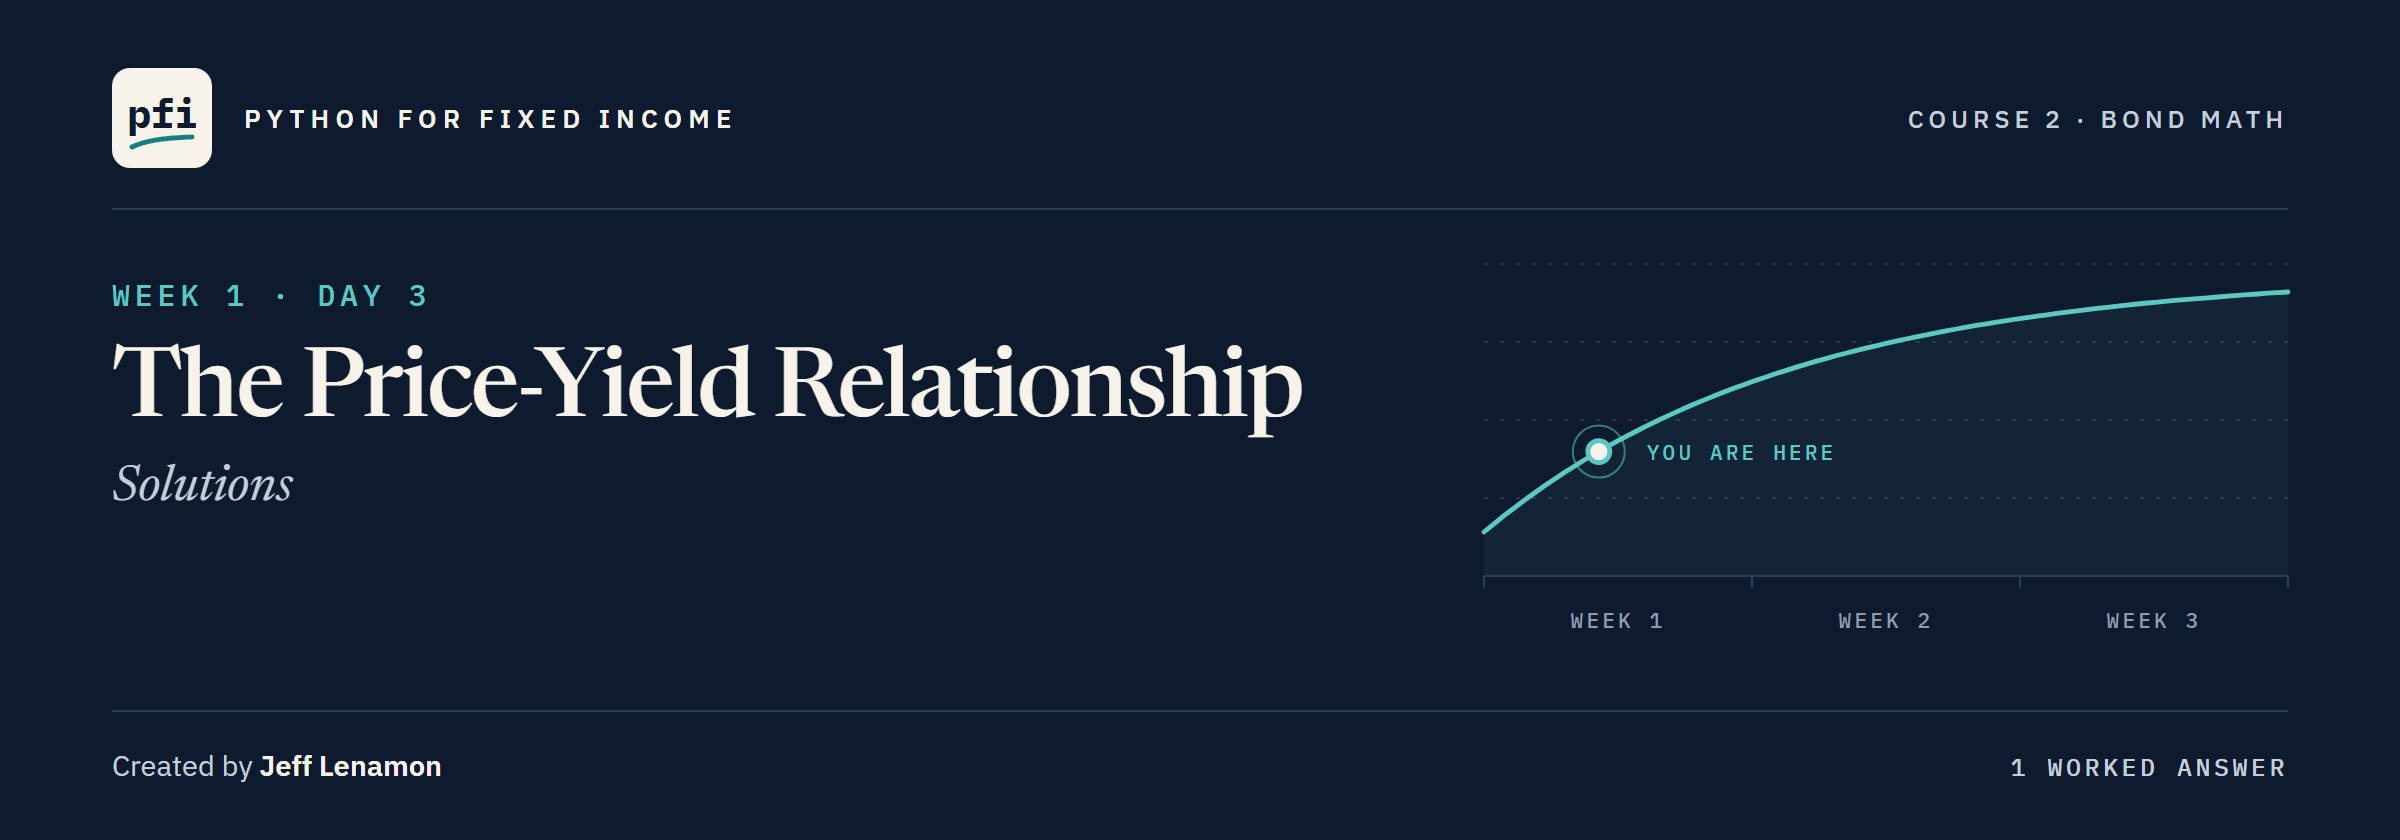

# The Price-Yield Relationship: Solutions

Week 1, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day3/03_the_price_yield_relationship_solutions.ipynb)

## Exercises

Run the next three cells first: the work folder with the module as the notebook ends, the imports and the bonds, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 03 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(3, after=3)

Work folder pfi_course2_03_k4w7q2xr: 2 data files, the module as notebook 03 left it, 3 commits


In [2]:
import importlib

import pandas as pd

import bondmath

tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
effect_rows = tvm[tvm['function'] == 'EFFECT']
nominal_rows = tvm[tvm['function'] == 'NOMINAL']
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'years': [4, 2, 6, 8],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
terms = list(zip(exercise_bonds['coupon_pct'], exercise_bonds['yield_pct'],
                 exercise_bonds['years']))
exercise_bonds['today'] = [bondmath.price_from_yield(c, y, t) for c, y, t in terms]
# the same yield, with 1 year left to run
exercise_bonds['one_year_left'] = [bondmath.price_from_yield(c, y, 1) for c, y, t in terms]
ex1_calderby_1y = exercise_bonds.loc[3, 'one_year_left']
# a premium bond's price falls toward 100
ex1_falling = list(exercise_bonds.loc[exercise_bonds['today'] > 100, 'ticker'])
check('Exercise 1 Calderby with 1 year left', ex1_calderby_1y, 99.67134685052798)
check('Exercise 1 falling toward 100', ex1_falling, ['TRNW'])

Exercise 1 Calderby with 1 year left: correct
Exercise 1 falling toward 100: correct


In [5]:
exercise_bonds[['ticker', 'today', 'one_year_left']].round(4)

,ticker,today,one_year_left
0,OSTV,99.3832,99.8323
1,TRNW,100.1423,100.0726
2,OSMC,98.2238,99.6636
3,CLDB,98.0052,99.6713


Calderby climbs from 98.0052 to 99.6713; only Tarnwick, coupon 4.375 above its 4.30 yield, falls, from 100.1423 to 100.0726.

### Exercise 2

In [6]:
today = bondmath.price_from_yield(5.0, 5.35, 6)
# 100 bp is 1 point of yield
ex2_down_points = bondmath.price_from_yield(5.0, 4.35, 6) - today
ex2_up_points = bondmath.price_from_yield(5.0, 6.35, 6) - today
ex2_larger = 'down' if abs(ex2_down_points) > abs(ex2_up_points) else 'up'
check('Exercise 2 yield down 100 bp', ex2_down_points, 5.176570543702951)
check('Exercise 2 yield up 100 bp', ex2_up_points, -4.873065902034114)
check('Exercise 2 larger move', ex2_larger, 'down')

Exercise 2 yield down 100 bp: correct
Exercise 2 yield up 100 bp: correct
Exercise 2 larger move: correct


+5.1766 against -4.8731: the bend again.
Excel's `PRICE` rows `tvm_price_14` and `tvm_price_15` return the two moved prices, 103.400335 and 93.350699.

### Exercise 3

In [7]:
# from twice a year to once, and from twice a year to four times
ex3_calderby_annual = bondmath.convert_yield(8.6, 2, 1)
ex3_osmere_quarterly = bondmath.convert_yield(5.35, 2, 4)
check('Exercise 3 Calderby annual', ex3_calderby_annual, 8.784899999999984)
check('Exercise 3 Osmere quarterly', ex3_osmere_quarterly, 5.314692553822908)

Exercise 3 Calderby annual: correct
Exercise 3 Osmere quarterly: correct


Calderby's 8.60 is 8.7849 annual, the largest gap of the four at the highest yield; Osmere's 5.35 is 5.3147 quarterly.

### Exercise 4

In [8]:
%%writefile -a bondmath.py


def price_change(old_price: float, new_price: float) -> tuple[float, float]:
    """The change from one price to another, in points and in percent.

    Units: prices per 100 of face. Returns (points per 100 of face, percent of the old price).
    Convention: a fall is negative. points = new_price - old_price; percent = points / old_price x 100.
    Excel: with the old price in B1 and the new in B2, =B2-B1 and =(B2-B1)/B1*100
    """
    # points: the plain difference, per 100 of face
    points = new_price - old_price
    # percent: the same difference as a share of where the price started
    percent = points / old_price * 100
    return points, percent

Appending to bondmath.py


In [9]:
%%writefile -a test_bondmath.py


def test_price_change_points_and_percent():
    # hand cases: 100 to 95 is 5 points and 5 percent down; 80 to 84 is 4 points and 5 percent up
    assert bondmath.price_change(100.0, 95.0) == pytest.approx((-5.0, -5.0))
    assert bondmath.price_change(80.0, 84.0) == pytest.approx((4.0, 5.0))
    # Excel's PRICE rows for Quorvane's 5.25 coupon: each step up in yield is a fall in price
    column = [row for row in tvm_rows("PRICE") if row["coupon_pct"] == "5.25"]
    assert len(column) == 7, "Quorvane's seven PRICE rows"
    for lower, higher in zip(column, column[1:]):
        points, percent = bondmath.price_change(float(lower["excel_value"]), float(higher["excel_value"]))
        assert points < 0 and percent < 0, higher["case_id"]

Appending to test_bondmath.py


In [10]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........                                                                [100%]
9 passed in 0.50s



In [11]:
importlib.reload(bondmath)
before = bondmath.price_from_yield(7.5, 7.7, 10)
after = bondmath.price_from_yield(7.5, 8.7, 10)
# the function returns two numbers: unpack them into two names
points, ex4_percent = bondmath.price_change(before, after)
print(f'Halvering, 7.70 to 8.70: {points:+.4f} points, {ex4_percent:+.4f} percent')

Halvering, 7.70 to 8.70: -6.5299 points, -6.6211 percent


In [12]:
check('Exercise 4 percent change', ex4_percent, -6.621129485219808)

Exercise 4 percent change: correct


`9 passed`; Halvering's -6.62 percent is 3.3's number.
`zip(column, column[1:])` pairs each row with the next one.

### Exercise 5: AI check

The bug: `yield_pct` is a percent, and the code used it as a decimal, so 5.40 went in as 540 percent and Quorvane came back 12.69.
The test stopped on the first row, `tvm_effect_01`: 11.250000 against 5.062500.
The round-trip test would have passed: the same mistake both ways cancels.
The fix: divide by 100 going in, multiply by 100 coming out.

In [13]:
def assistant_convert_yield(yield_pct, from_frequency, to_frequency):
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    """
    # the fix, part 1: a percent, so divide by 100 for the decimal rate
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # the fix, part 2: back to percent, as the docstring promises
    return period_rate * to_frequency * 100

In [14]:
for case, rate, frequency, excel in zip(effect_rows.index, effect_rows['rate_pct'],
                                        effect_rows['frequency'], effect_rows['excel_value']):
    result = assistant_convert_yield(rate, frequency, 1)
    # Excel returns a decimal, the docstring promises a percent
    assert abs(result - excel * 100) < 1e-9, f'{case}: {result:.6f} against {excel * 100:.6f}'
for case, rate, frequency, excel in zip(nominal_rows.index, nominal_rows['rate_pct'],
                                        nominal_rows['frequency'], nominal_rows['excel_value']):
    result = assistant_convert_yield(rate, 1, frequency)
    assert abs(result - excel * 100) < 1e-9, f'{case}: {result:.6f} against {excel * 100:.6f}'
print(f'All {len(effect_rows) + len(nominal_rows)} EFFECT and NOMINAL rows match Excel')

All 22 EFFECT and NOMINAL rows match Excel


In [15]:
ex5_quorvane = assistant_convert_yield(5.4, 2, 1)
ex5_rows = len(effect_rows) + len(nominal_rows)
check('Exercise 5 Quorvane annual', ex5_quorvane, 5.472899999999981)
check('Exercise 5 rows checked', ex5_rows, 22)

Exercise 5 Quorvane annual: correct
Exercise 5 rows checked: correct


[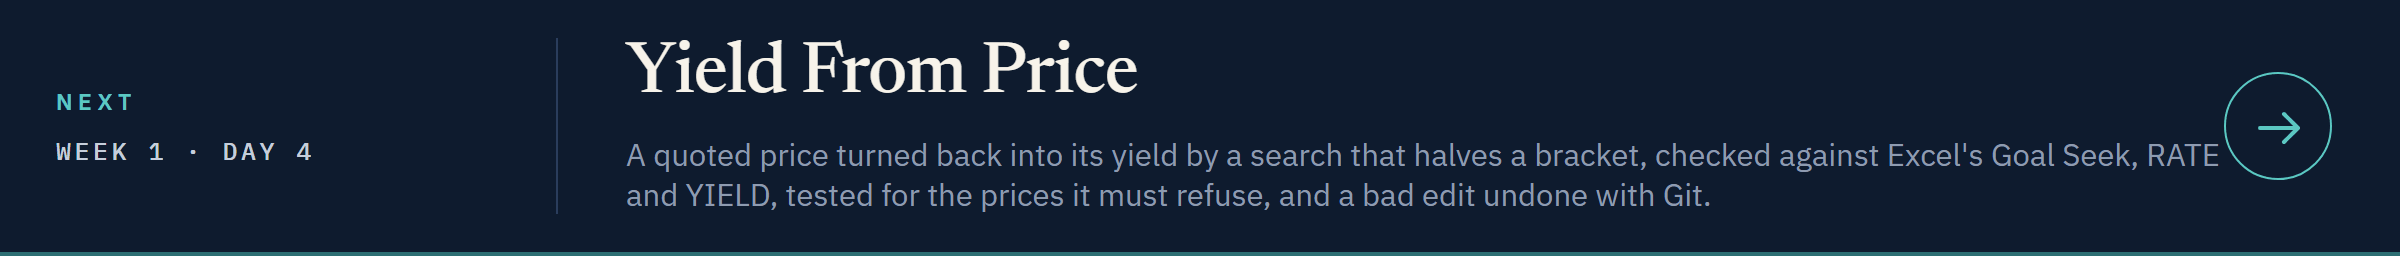](../day4/04_yield_from_price.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day4/04_yield_from_price.ipynb)